In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
path = os.getcwd()
path = os.path.split(path)[0]
path = os.path.split(path)[0]
path = os.path.join(path, r"data\Combined_Residential_Sold.csv")


In [3]:
sold = pd.read_csv(path)

C:\Users\fistb\AppData\Local\Temp\ipykernel_29716\3103233035.py:1: DtypeWarning: Columns (46: BuyerAgencyCompensationType, 65: FireplaceYN, 79: latfilled, 80: lonfilled, 81: BuyerAgentAOR, 82: ListAgentAOR, 83: OriginatingSystemName, 84: OriginatingSystemSubName) have mixed types. Specify dtype option on import or set low_memory=False.
  sold = pd.read_csv(path)


In [4]:
shape = sold.shape
print(f"Sold Dataset has {shape[0]} Rows with {shape[1]} Columns!")

Sold Dataset has 414054 Rows with 85 Columns!


In [5]:
sold.columns

Index(['Unnamed: 0', 'Flooring', 'ViewYN', 'WaterfrontYN', 'BasementYN',
       'PoolPrivateYN', 'OriginalListPrice', 'ListingKey', 'ListAgentEmail',
       'CloseDate', 'ClosePrice', 'ListAgentFirstName', 'ListAgentLastName',
       'Latitude', 'Longitude', 'UnparsedAddress', 'PropertyType',
       'LivingArea', 'ListPrice', 'DaysOnMarket', 'ListOfficeName',
       'BuyerOfficeName', 'CoListOfficeName', 'ListAgentFullName',
       'CoListAgentFirstName', 'CoListAgentLastName', 'BuyerAgentMlsId',
       'BuyerAgentFirstName', 'BuyerAgentLastName', 'FireplacesTotal',
       'AssociationFeeFrequency', 'AboveGradeFinishedArea',
       'ListingKeyNumeric', 'MLSAreaMajor', 'TaxAnnualAmount',
       'CountyOrParish', 'MlsStatus', 'ElementarySchool', 'AttachedGarageYN',
       'ParkingTotal', 'BuilderName', 'PropertySubType', 'LotSizeAcres',
       'SubdivisionName', 'BuyerOfficeAOR', 'YearBuilt',
       'BuyerAgencyCompensationType', 'StreetNumberNumeric', 'ListingId',
       'BathroomsTotal

In [6]:
na_counts = sold.isna().sum().to_dict()

In [7]:
Majoritiy_Na_columns = {}
for column in na_counts:
    percentage_missing = na_counts[column] / 414054 
    if percentage_missing > 0.9:
        Majoritiy_Na_columns[column] = percentage_missing

In [8]:
print("The Following Columns have Na Values for 90% of their values:")

for column in Majoritiy_Na_columns:
    print(f"{column} - {(Majoritiy_Na_columns[column]*100):.2f}%")

print("All  of these columns should be dropped.")

The Following Columns have Na Values for 90% of their values:
WaterfrontYN - 99.94%
BasementYN - 98.04%
FireplacesTotal - 100.00%
AboveGradeFinishedArea - 100.00%
TaxAnnualAmount - 100.00%
BuilderName - 95.11%
TaxYear - 100.00%
BuildingAreaTotal - 93.00%
ElementarySchoolDistrict - 100.00%
CoBuyerAgentFirstName - 90.91%
BelowGradeFinishedArea - 99.42%
BusinessType - 100.00%
CoveredSpaces - 100.00%
LotSizeDimensions - 95.14%
MiddleOrJuniorSchoolDistrict - 100.00%
All  of these columns should be dropped.


In [9]:
Numeric_Analysis_cols = [
    "ClosePrice",
    "ListPrice",
    "OriginalListPrice",
    "LivingArea",
    "LotSizeAcres",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "DaysOnMarket",
    "YearBuilt"
]

In [10]:
len(Numeric_Analysis_cols)

9

(array([4.13963e+05, 1.80000e+01, 2.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00, 1.00000e+00]),
 array([  0. ,  17.5,  35. ,  52.5,  70. ,  87.5, 105. , 122.5, 140. ,
        157.5, 175. ]),
 <BarContainer object of 10 artists>)

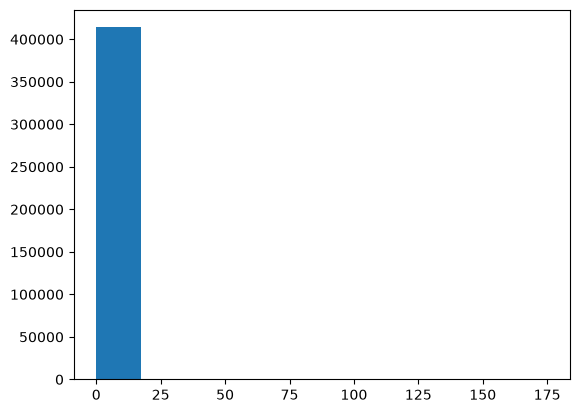

In [11]:
plt.hist(sold["BathroomsTotalInteger"])

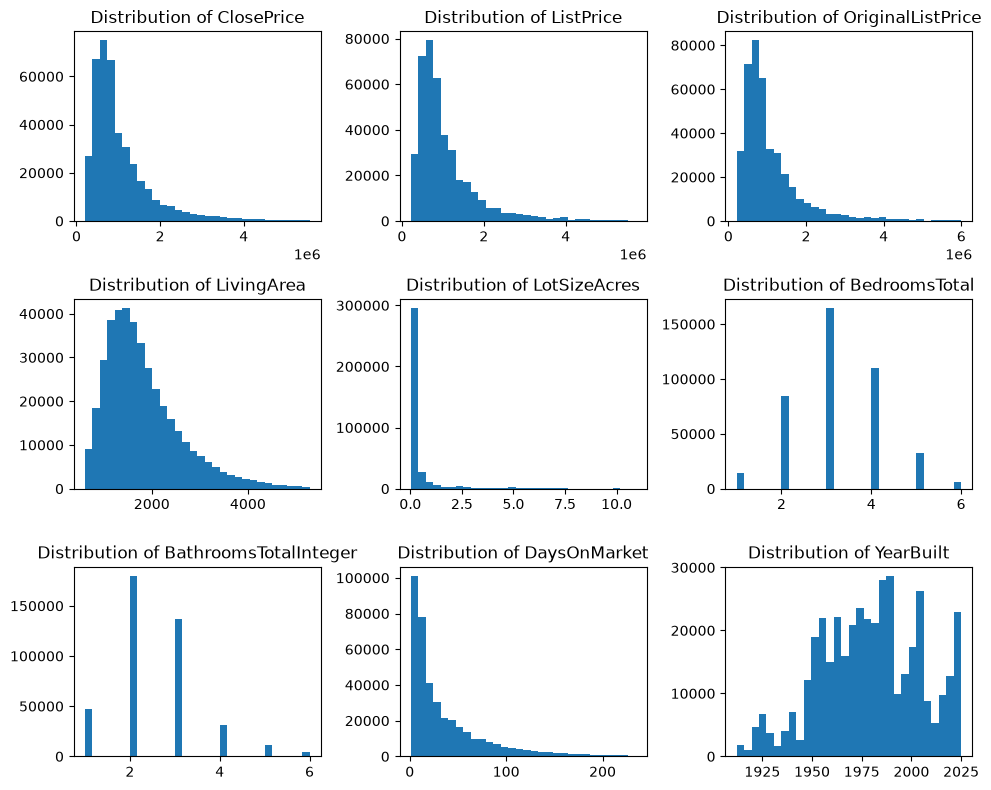

In [12]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 8))

for row in range(3):
    for col in range(3):
        indx = col + row * 3
        s = sold[Numeric_Analysis_cols[indx]].dropna()
        s = s[s > 0]                      
        lo, hi = s.quantile([0.01, 0.99])
        s = s[(s >= lo) & (s <= hi)]     
        axes[row, col].hist(s, bins=30)
        axes[row, col].set_title(f"Distribution of {Numeric_Analysis_cols[indx]}")
    
        
plt.tight_layout()
plt.show()

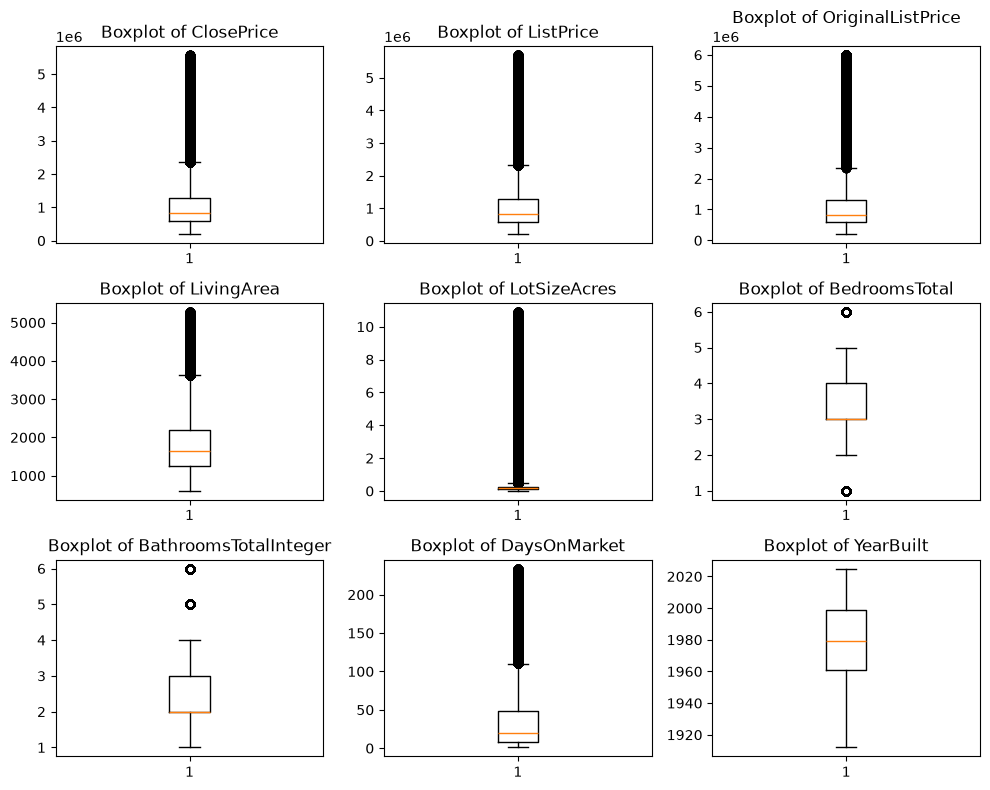

In [13]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 8))

for row in range(3):
    for col in range(3):
        indx = col + row * 3
        s = sold[Numeric_Analysis_cols[indx]].dropna()
        s = s[s > 0]                      
        lo, hi = s.quantile([0.01, 0.99])
        s = s[(s >= lo) & (s <= hi)]     
        axes[row, col].boxplot(s)
        axes[row, col].set_title(f"Boxplot of {Numeric_Analysis_cols[indx]}")
    
        
plt.tight_layout()
plt.show()

In [14]:
sold.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,414054.0,2.070265e+05,1.195272e+05,0.000000e+00,1.035132e+05,2.070265e+05,3.105398e+05,4.140530e+05
OriginalListPrice,413298.0,1.225401e+06,6.709938e+06,0.000000e+00,5.850000e+05,8.250000e+05,1.299000e+06,1.390000e+09
ListingKey,414054.0,1.098117e+09,3.131734e+07,4.216785e+08,1.075489e+09,1.097306e+09,1.118678e+09,1.159569e+09
ClosePrice,414052.0,1.193864e+06,6.290122e+06,0.000000e+00,5.750000e+05,8.230000e+05,1.300000e+06,9.895000e+08
Latitude,409950.0,3.470111e+01,1.742684e+00,-1.174725e+02,3.373563e+01,3.405408e+01,3.470178e+01,5.613037e+01
Longitude,409950.0,-1.186298e+02,2.978720e+00,-1.776467e+02,-1.191497e+02,-1.180332e+02,-1.172676e+02,3.290000e+02
LivingArea,413820.0,1.903791e+03,2.647620e+04,0.000000e+00,1.248000e+03,1.642000e+03,2.219000e+03,1.702132e+07
ListPrice,414054.0,1.140462e+06,1.359497e+06,5.250000e+02,5.761670e+05,8.150000e+05,1.295000e+06,1.375000e+08
DaysOnMarket,414054.0,3.735512e+01,5.359246e+01,-2.880000e+02,8.000000e+00,1.800000e+01,4.800000e+01,1.243000e+04
FireplacesTotal,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# EDA Questions

1. What is the Median and Average of Clos Prices
* Median is 1.3 Million while Average is 1.19 Million. Seems like there are outliers brings the mean value down.


In [15]:
Sold_above_listing_price = sold['ListPrice'] < sold['ClosePrice']  
Sold_above_listing_price.value_counts() / len(Sold_above_listing_price)

False    0.599023
True     0.400977
Name: count, dtype: float64

2. What Percentage of Homes were sold above listing price?
* 60% of Homes were sold above listing price, while 40% were sold either at Listing price or lower.

In [16]:
days = sold['DaysOnMarket']
days = days.value_counts().to_dict()
sorted_key = sorted(days.keys())
total, count = 0, len(sold['DaysOnMarket'])
for day in sorted_key:
    if day < 0:
        continue
    total += days[day] / count
    if total > 0.9:
        print(f"90% of homes are sold by Day {day}.")
        break




90% of homes are sold by Day 94.


3. What does the Days on Market distribution look like?
* As days progress on the market, the less likely a house is on the market. 90% of all homes are sold before or by 94 Days(3 Months). 

# Filtering

In [17]:
print("Droping Columns with above 90% NA Values.")
sold = sold.drop(columns = Majoritiy_Na_columns.keys())


Droping Columns with above 90% NA Values.


In [18]:
print("Droping all rows with negative values.")

sold = sold[~(sold[Numeric_Analysis_cols]< 0).any(axis=1)]

Droping all rows with negative values.


In [19]:
print("Dropping all Outliers: Top 1% and Bottom 1%")

lower = sold[Numeric_Analysis_cols].quantile(0.01)
upper = sold[Numeric_Analysis_cols].quantile(0.99)

mask = (
    (sold[Numeric_Analysis_cols] >= lower) &
    (sold[Numeric_Analysis_cols] <= upper)
).all(axis=1)

sold = sold[mask]

Dropping all Outliers: Top 1% and Bottom 1%


In [20]:
sold.shape

(354197, 70)

In [22]:
sold.to_csv("Filtered_sold_data.csv")

The Filtering Logic is the following:
* Drop all columns with 90% Na Values
* Drop all negative values in the important columns - These are errors. E.g. You can't negative days on Market or negative prices. 
* Drop all Outliers in the important columns: Top 1% and Bottom 1%